# Register Fault Injection — Resilience Analysis
**Model:** Fashion-MNIST Image Classification (INT8 quantized TFLite)  
**Target:** RISC-V registers (transient bit-flip)  
**Campaign:** `registerfi_image_classification_fashsion_mnist_transient`  
**Sampling:** Stratified per operator — 95% confidence, 5% margin

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path(".")  # notebook lives inside the run directory

SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50",
    "Good": "#81C784",
    "Acceptable": "#FFC107",
    "Warning": "#FF9800",
    "Critical": "#F44336",
    "Crash": "#B71C1C",
}

CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

## 1. Data Loading

In [2]:
df = pd.read_csv(RUN_DIR / "classified_results.csv")
pop = pd.read_csv(RUN_DIR / "register_population.csv")
sel = pd.read_csv(RUN_DIR / "selected_register_faults.csv")
sel_by_layer = pd.read_csv(RUN_DIR / "selected_register_faults_by_layer.csv")
pop_by_op = pd.read_csv(RUN_DIR / "register_population_by_operator.csv")
operators = pd.read_csv(RUN_DIR / "all_operator_instances.csv")

import json
with open(RUN_DIR / "run_manifest.json") as f:
    manifest = json.load(f)

# Merge register metadata into classified results
reg_meta = sel[["fault_id", "register_name", "register_class", "register_id"]].drop_duplicates("fault_id")
df = df.merge(reg_meta, on="fault_id", how="left", suffixes=("", "_meta"))

# Ensure register_name and register_class columns are populated
if "register_name_meta" in df.columns:
    df["register_name"] = df["register_name"].fillna(df["register_name_meta"])
if "register_class" not in df.columns and "register_class_meta" in df.columns:
    df["register_class"] = df["register_class_meta"]

print(f"Total classified results : {len(df):,}")
print(f"Unique faults injected   : {df['fault_id'].nunique():,}")
print(f"Images per fault         : {len(df) // df['fault_id'].nunique()}")
print(f"Population size          : {len(pop):,}")
print(f"Operators targeted       : {df['operator_index'].nunique()}")
print(f"Registers targeted       : {df['register_name'].nunique()}")
print(f"Fault model              : {manifest.get('campaign_type', 'register')}")
print(f"Fault duration           : {manifest.get('fault_duration', 'transient')}")
df.head(3)

Total classified results : 139,000
Unique faults injected   : 1,390
Images per fault         : 100
Population size          : 4,960
Operators targeted       : 5
Registers targeted       : 31
Fault model              : register
Fault duration           : transient


,event,phase,mode,fault_model,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,...,delay_us,bit_index,mean_duration_us,samples,golden_pred_class_ref,golden_top1_prob_ref,fault_class,register_name_meta,register_class,register_id_meta
0,result,fault,fault,register,3.0,0.0,1.0,1.0,0.996094,1.0,...,14641.0,3.0,NaN,NaN,1.0,0.996094,Masked,ra,caller_saved,0
1,result,fault,fault,register,3.0,1.0,6.0,4.0,0.554688,4.0,...,14641.0,3.0,NaN,NaN,4.0,0.554688,Masked,ra,caller_saved,0
2,result,fault,fault,register,3.0,2.0,8.0,8.0,0.996094,8.0,...,14641.0,3.0,NaN,NaN,8.0,0.996094,Masked,ra,caller_saved,0


## 2. Overall Fault Classification Distribution

,Count,Percentage (%)
fault_class,,
Masked,95753.0,68.89
Good,115.0,0.08
Acceptable,3274.0,2.36
Warning,1576.0,1.13
Critical,12782.0,9.20
Crash,25500.0,18.35
TOTAL,139000.0,100.00


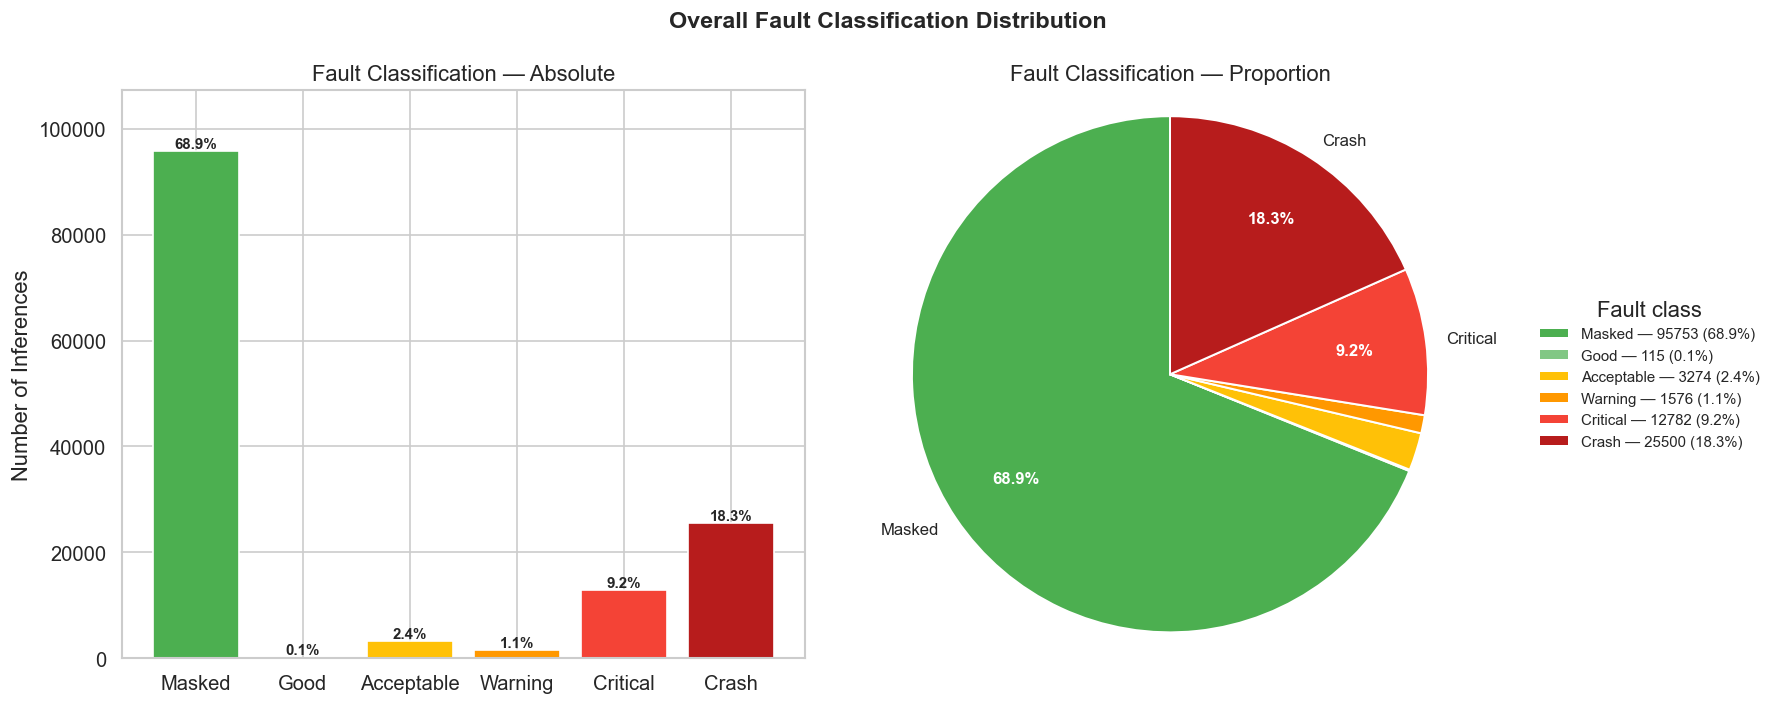

In [3]:
fc_counts = df["fault_class"].value_counts()
fc_ordered = fc_counts.reindex(SEVERITY_ORDER).dropna().astype(int)
fc_pct = fc_ordered / len(df) * 100

summary_table = pd.DataFrame({"Count": fc_ordered, "Percentage (%)": fc_pct.round(2)})
summary_table.loc["TOTAL"] = [len(df), 100.0]
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
colors = [SEVERITY_COLORS.get(c, "#999") for c in fc_ordered.index]
bars = axes[0].bar(fc_ordered.index, fc_ordered.values, color=colors, edgecolor="white")
for bar, pct in zip(bars, fc_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Number of Inferences")
axes[0].set_title("Fault Classification — Absolute")
axes[0].margins(y=0.12)

# Pie chart — rótulos só para fatias >= 3%, demais vão só na legenda
THRESH = 3.0  # %

def _autopct(pct):
    return f"{pct:.1f}%" if pct >= THRESH else ""

pie_labels = [name if pct >= THRESH else "" for name, pct in zip(fc_ordered.index, fc_pct.values)]

wedges, texts, autotexts = axes[1].pie(
    fc_ordered.values,
    labels=pie_labels,
    colors=colors,
    autopct=_autopct,
    startangle=90,
    pctdistance=0.72,
    labeldistance=1.08,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=10),
)
for t in autotexts:
    t.set_fontweight("bold")
    t.set_color("white")

axes[1].set_title("Fault Classification — Proportion")
axes[1].axis("equal")

# Legenda completa (inclui fatias pequenas omitidas do gráfico)
legend_labels = [f"{name} — {cnt} ({pct:.1f}%)"
                 for name, cnt, pct in zip(fc_ordered.index, fc_ordered.values, fc_pct.values)]
axes[1].legend(
    wedges, legend_labels,
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9,
    frameon=False,
)

fig.suptitle("Overall Fault Classification Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_overall_classification.png", bbox_inches="tight")
plt.show()

## 3. Resilience per Register

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
register_name,,,,,,,,
s4,3500,94,106,82,814,2400,0.9183,0.9417
ra,3800,540,0,0,0,3260,0.8579,0.8579
s1,4600,1050,93,63,1589,1800,0.7367,0.7504
a0,5400,2645,74,34,345,2298,0.4894,0.4957
s3,4100,1863,50,210,462,1500,0.4785,0.5298
s7,4400,2206,146,42,506,1500,0.4559,0.4655
s8,4800,2637,58,28,1170,900,0.4312,0.4371
a7,4600,2419,136,76,1691,272,0.4267,0.4433
a4,4200,2053,55,330,1592,143,0.4131,0.4917


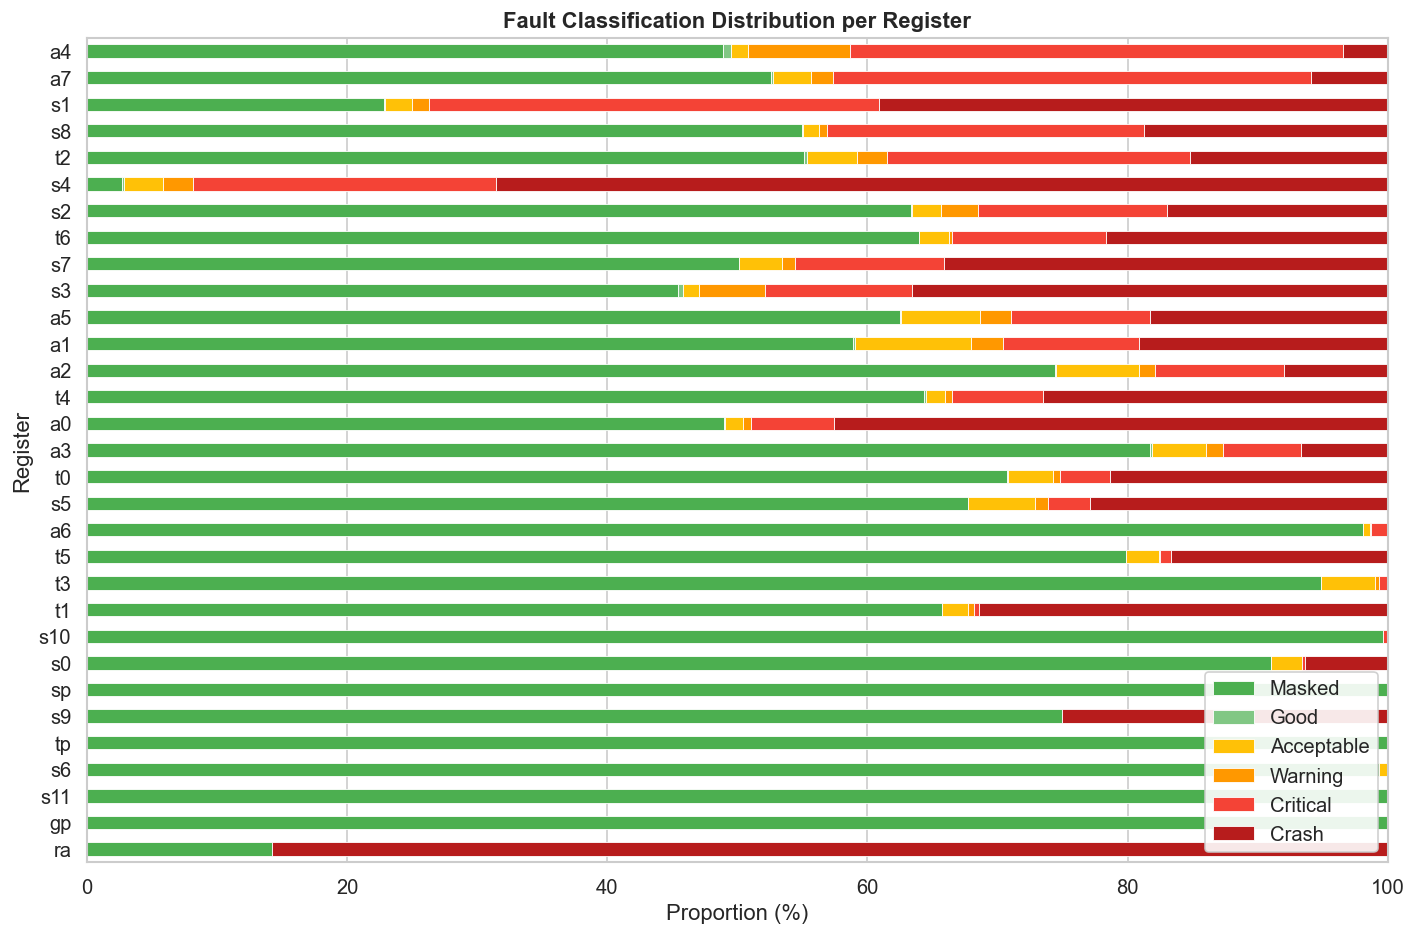

In [4]:
# Aggregate fault class distribution per register
reg_fc = df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
reg_fc = reg_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
reg_fc["total"] = reg_fc.sum(axis=1)
reg_fc["critical_rate"] = (reg_fc.get("Critical", 0) + reg_fc.get("Crash", 0)) / reg_fc["total"]
reg_fc["degraded_rate"] = reg_fc[[c for c in DEGRADED_SET if c in reg_fc.columns]].sum(axis=1) / reg_fc["total"]
reg_fc = reg_fc.sort_values("critical_rate", ascending=False)

display(reg_fc[["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]].round(4))

# Stacked bar — percentage per register
reg_pct = reg_fc[SEVERITY_ORDER].div(reg_fc["total"], axis=0) * 100
reg_pct_sorted = reg_pct.sort_values("Critical", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
reg_pct_sorted.plot.barh(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white", linewidth=0.5,
)
ax.set_xlabel("Proportion (%)")
ax.set_ylabel("Register")
ax.set_title("Fault Classification Distribution per Register", fontweight="bold")
ax.legend(loc="lower right", framealpha=0.9)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_register.png", bbox_inches="tight")
plt.show()

## 4. Resilience per Register Class
Registers are grouped by their RISC-V ABI classification: **caller-saved** (temporary), **callee-saved** (preserved), and **special** (sp, gp, tp, ra).

fault_class,Masked,Good,Acceptable,Warning,Critical,Crash,total,critical_rate,degraded_rate
register_class,,,,,,,,,
callee_saved,36257,36,941,605,5392,11369,54600,0.3070,0.3181
caller_saved,46096,79,2333,971,7390,14131,71000,0.3031,0.3168
special,13400,0,0,0,0,0,13400,0.0000,0.0000


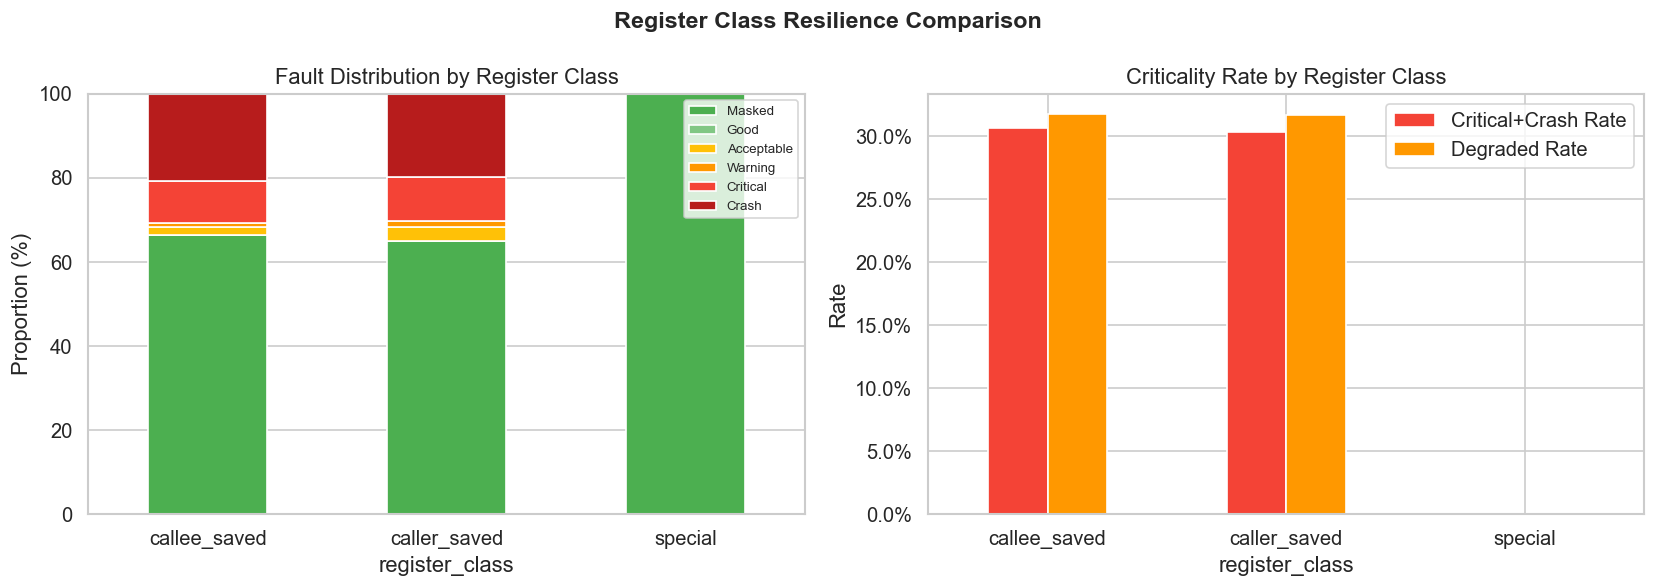

In [5]:
cls_fc = df.groupby("register_class")["fault_class"].value_counts().unstack(fill_value=0)
cls_fc = cls_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
cls_fc["total"] = cls_fc.sum(axis=1)
cls_fc["critical_rate"] = (cls_fc.get("Critical", 0) + cls_fc.get("Crash", 0)) / cls_fc["total"]
cls_fc["degraded_rate"] = cls_fc[[c for c in DEGRADED_SET if c in cls_fc.columns]].sum(axis=1) / cls_fc["total"]

display(cls_fc.round(4))

cls_pct = cls_fc[SEVERITY_ORDER].div(cls_fc["total"], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cls_pct.plot.bar(
    stacked=True, ax=axes[0],
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
axes[0].set_ylabel("Proportion (%)")
axes[0].set_title("Fault Distribution by Register Class")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(axis="x", rotation=0)

# Critical + Crash rate comparison
cls_crit = cls_fc[["critical_rate", "degraded_rate"]].copy()
cls_crit.columns = ["Critical+Crash Rate", "Degraded Rate"]
cls_crit.plot.bar(ax=axes[1], color=["#F44336", "#FF9800"], edgecolor="white")
axes[1].set_ylabel("Rate")
axes[1].set_title("Criticality Rate by Register Class")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Register Class Resilience Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_register_class_resilience.png", bbox_inches="tight")
plt.show()

## 5. Resilience per Operator (Layer)

In [6]:
df.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'operator_index',
       'operator_name', 'register_id', 'register_name', 'time_slot_index',
       'time_slot_count', 'delay_us', 'bit_index', 'mean_duration_us',
       'samples', 'golden_pred_class_ref', 'golden_top1_prob_ref',
       'fault_class', 'register_name_meta', 'register_class',
       'register_id_meta'],
      dtype='str')

In [7]:
df['operator_index'].value_counts()

operator_index
0.0    27800
2.0    27800
4.0    27800
6.0    27800
7.0    27800
Name: count, dtype: int64

In [8]:
d = pd.read_csv('results.csv')

C:\Users\ronal\AppData\Local\Temp\ipykernel_18668\1667207595.py:1: DtypeWarning: Columns (0: operator_name) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv('results.csv')


In [18]:
d.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'operator_index',
       'operator_name', 'register_id', 'register_name', 'time_slot_index',
       'time_slot_count', 'delay_us', 'bit_index', 'mean_duration_us',
       'samples'],
      dtype='str')

In [9]:
d['operator_name'].value_counts()

operator_name
CONV_2D            3
FULLY_CONNECTED    2
Name: count, dtype: int64

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
FULLY_CONNECTED,55600,36833,1030,726,5223,11729,0.3049,0.3179
CONV_2D,83400,58920,2244,850,7559,13771,0.2558,0.2659


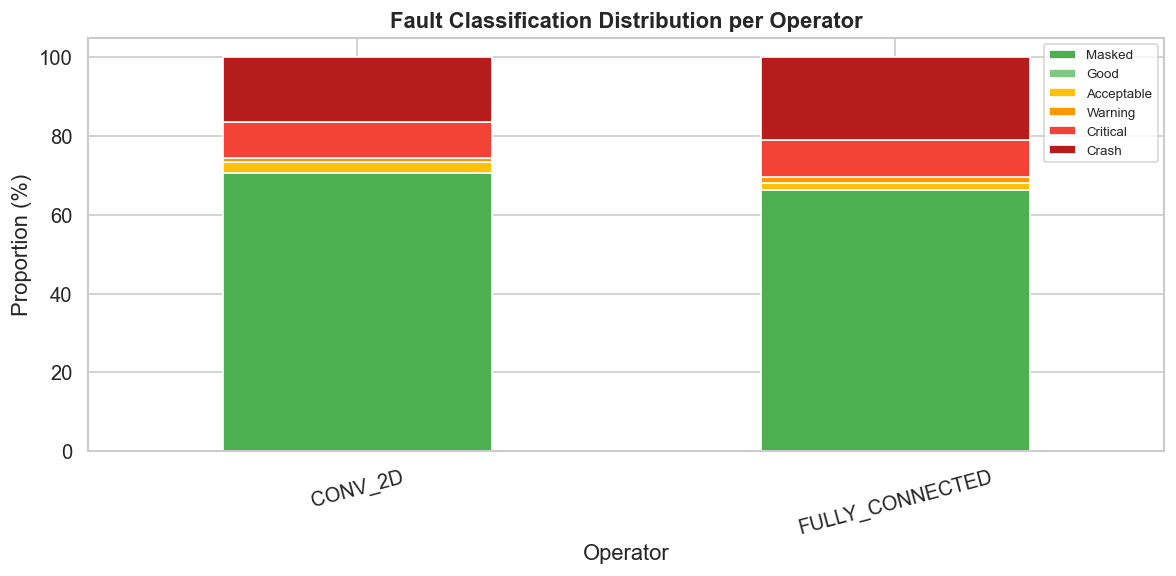

In [10]:
import numpy as np

# Usa apenas o nome real do operador
df["op_label"] = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

op_fc = op_fc.sort_values("critical_rate", ascending=False)

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den, axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator")
ax.set_title("Fault Classification Distribution per Operator", fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 6. Register × Operator Criticality Heatmap

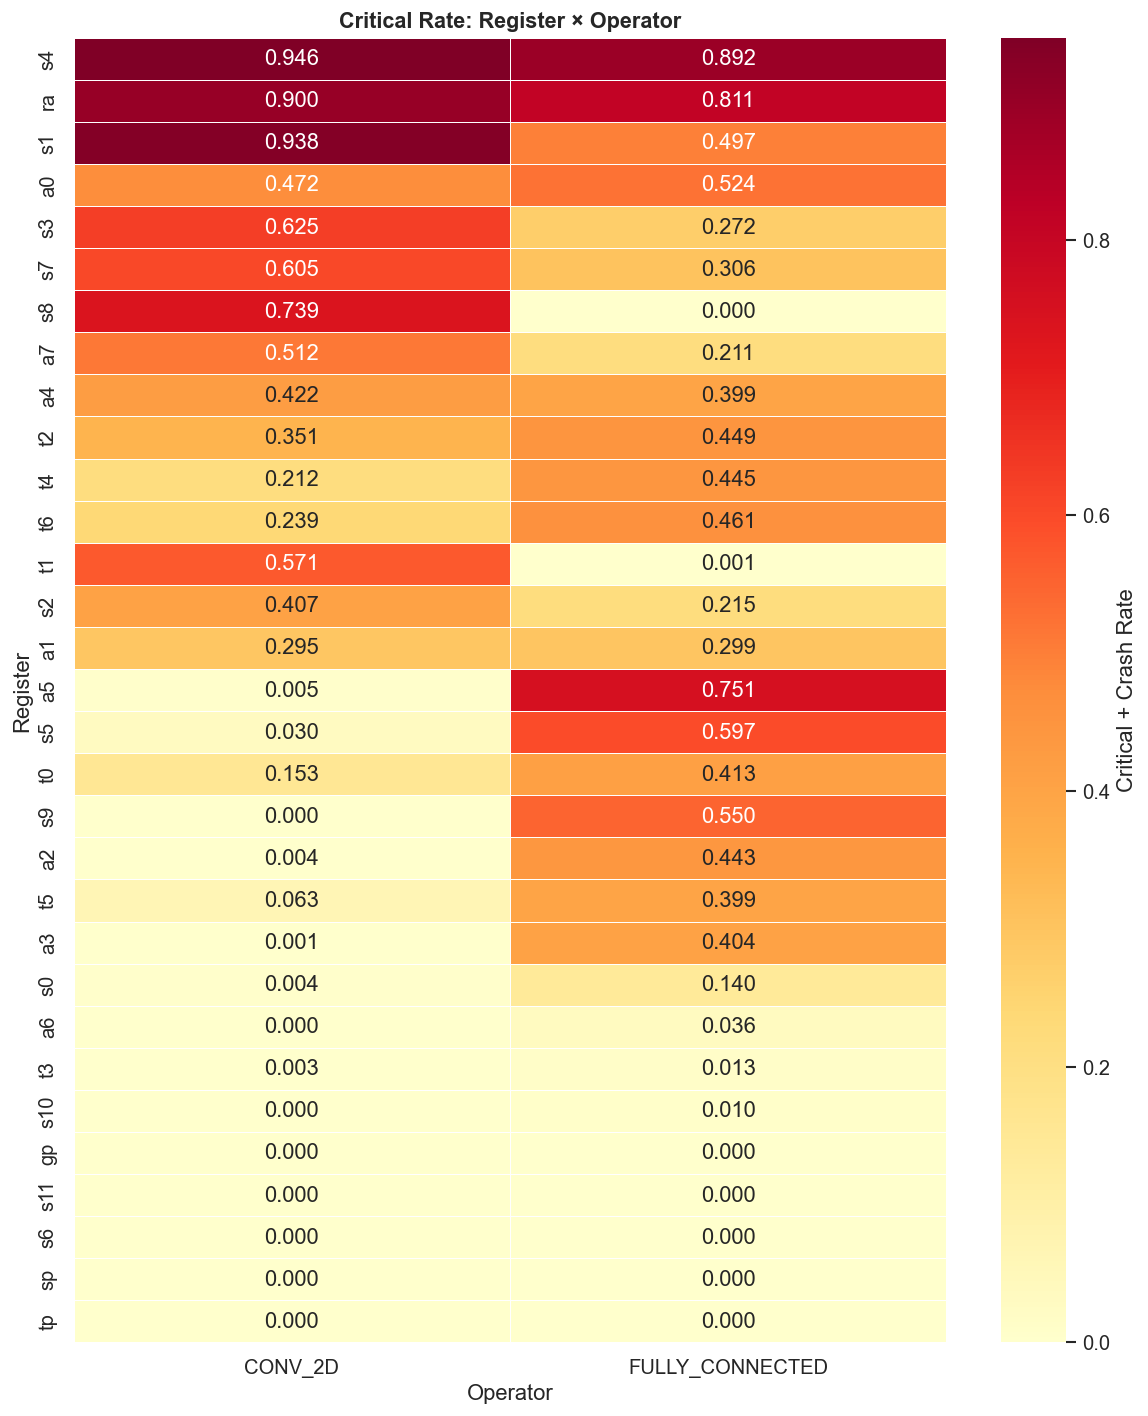

In [11]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)

# Sort registers by overall critical rate
reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=False).index
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

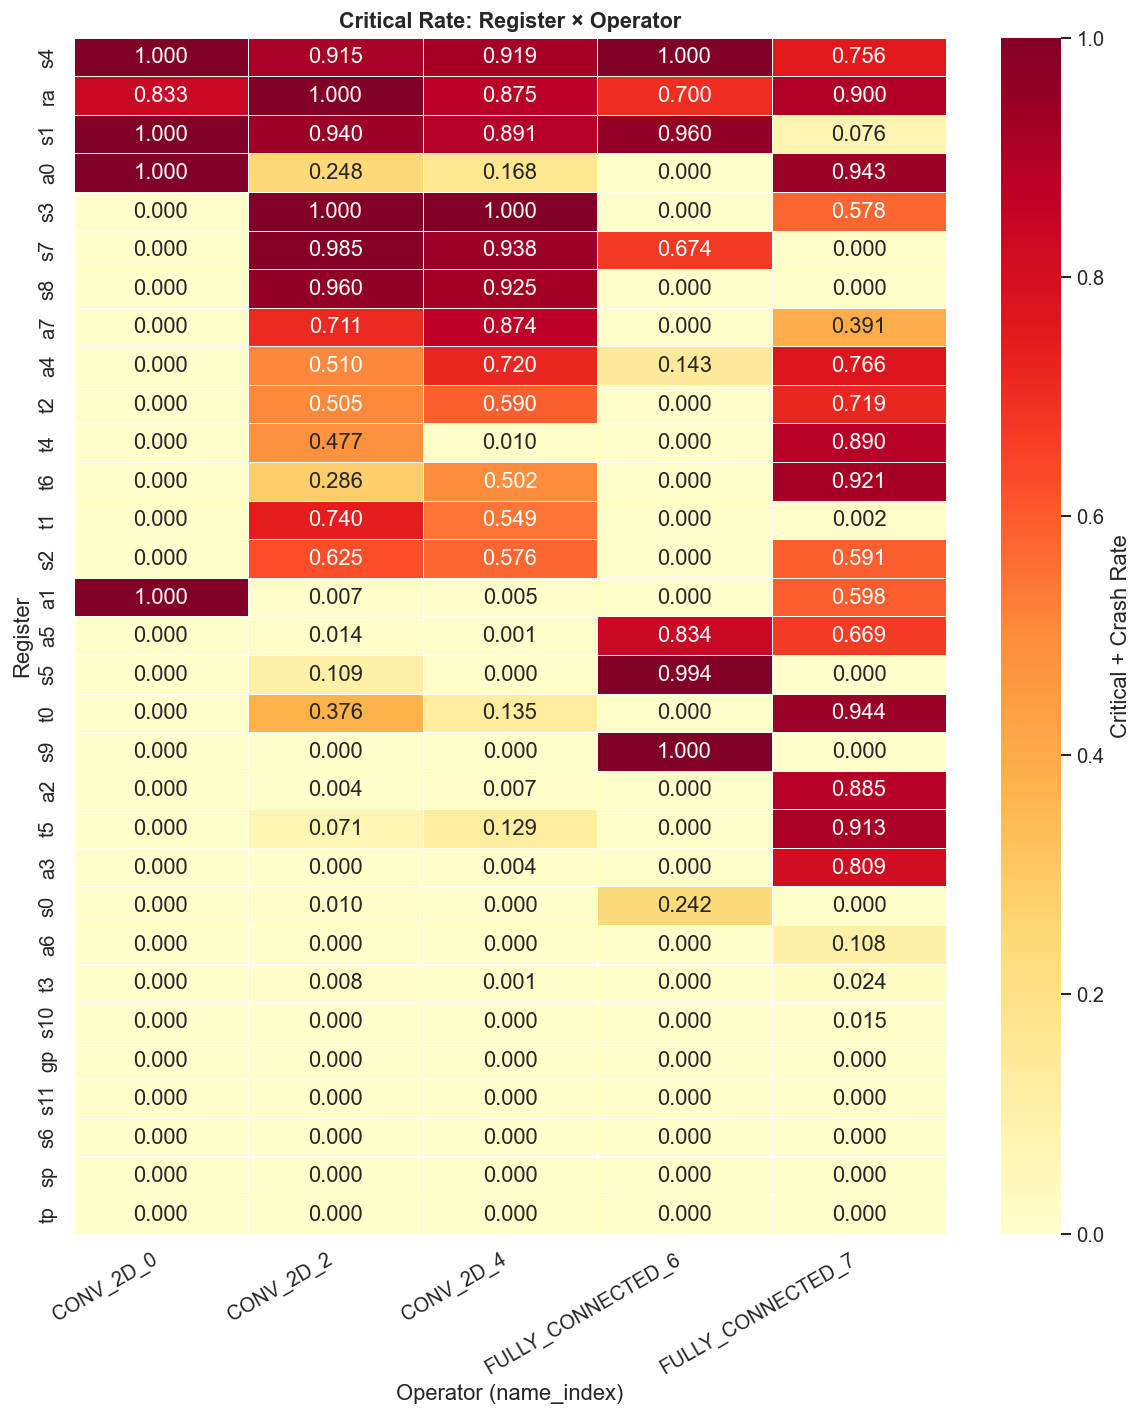

In [12]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Build "operator_name_operator_index" label (e.g. CONV_2D_0, CONV_2D_2)
op_name = (
    df["operator_name"].astype("string").str.strip()
    .replace("", pd.NA).fillna("Unknown")
)
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64").astype("string").fillna("NA")
)
df["op_full"] = op_name + "_" + op_idx

heatmap_data = (
    df.groupby(["register_name", "op_full"])
      .apply(critical_rate)
      .unstack(fill_value=0)
)

# Order columns by numeric operator_index when possible
col_order = sorted(
    heatmap_data.columns,
    key=lambda c: (int(c.rsplit("_", 1)[1]) if c.rsplit("_", 1)[1].isdigit() else 10**9, c),
)
heatmap_data = heatmap_data[col_order]

# Sort registers by overall critical rate
reg_order = (
    df.groupby("register_name").apply(critical_rate)
      .sort_values(ascending=False).index
)
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator (name_index)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,27800,23700,0,0,0,4100,0.1475,0.1475
2_CONV_2D,27800,18573,896,233,3018,5049,0.2902,0.2986
4_CONV_2D,27800,16647,1348,617,4541,4622,0.3296,0.3518
6_FULLY_CONNECTED,27800,21047,161,29,606,5957,0.2361,0.2371
7_FULLY_CONNECTED,27800,15786,869,697,4617,5772,0.3737,0.3988


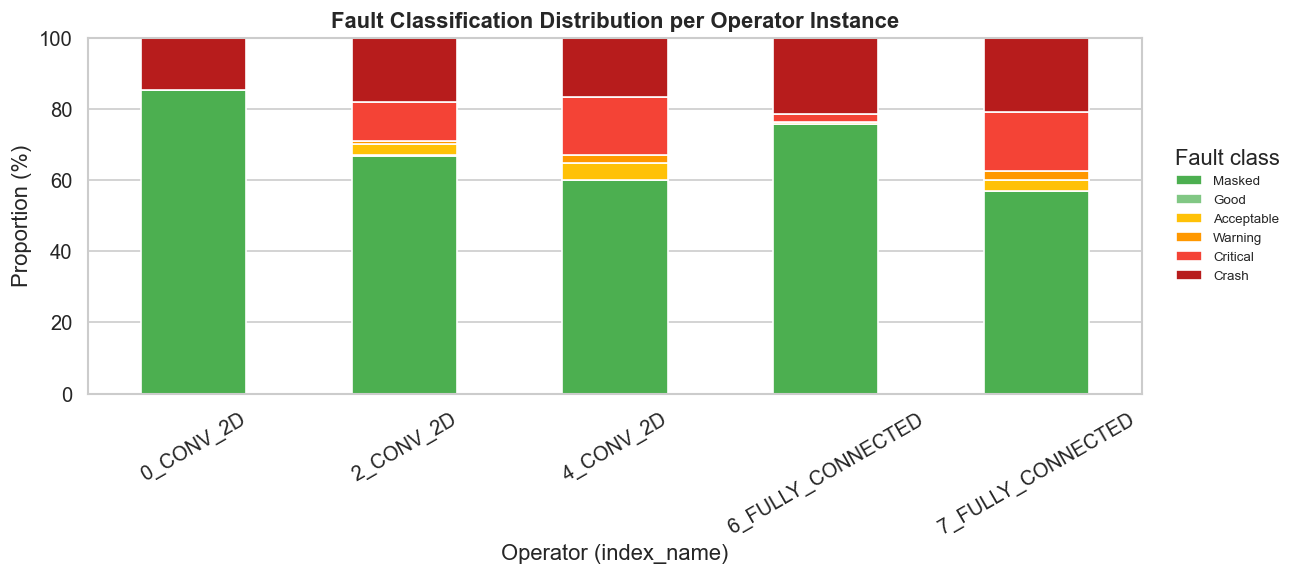

In [13]:
import numpy as np

# Combina operator_index + operator_name para distinguir instâncias do mesmo operador
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)
op_name = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
df["op_label"] = op_idx + "_" + op_name

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

# Ordena por op_index numérico (quando disponível) para manter ordem natural da rede
def _sort_key(label: str):
    head = label.split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

op_fc = op_fc.loc[sorted(op_fc.index, key=_sort_key)]

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den.loc[op_fc.index], axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator (index_name)")
ax.set_title("Fault Classification Distribution per Operator Instance", fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=False,
)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 7. Bit-Position Vulnerability Analysis
Evaluates whether higher-order bits (MSB) lead to more critical failures than lower-order bits (LSB).

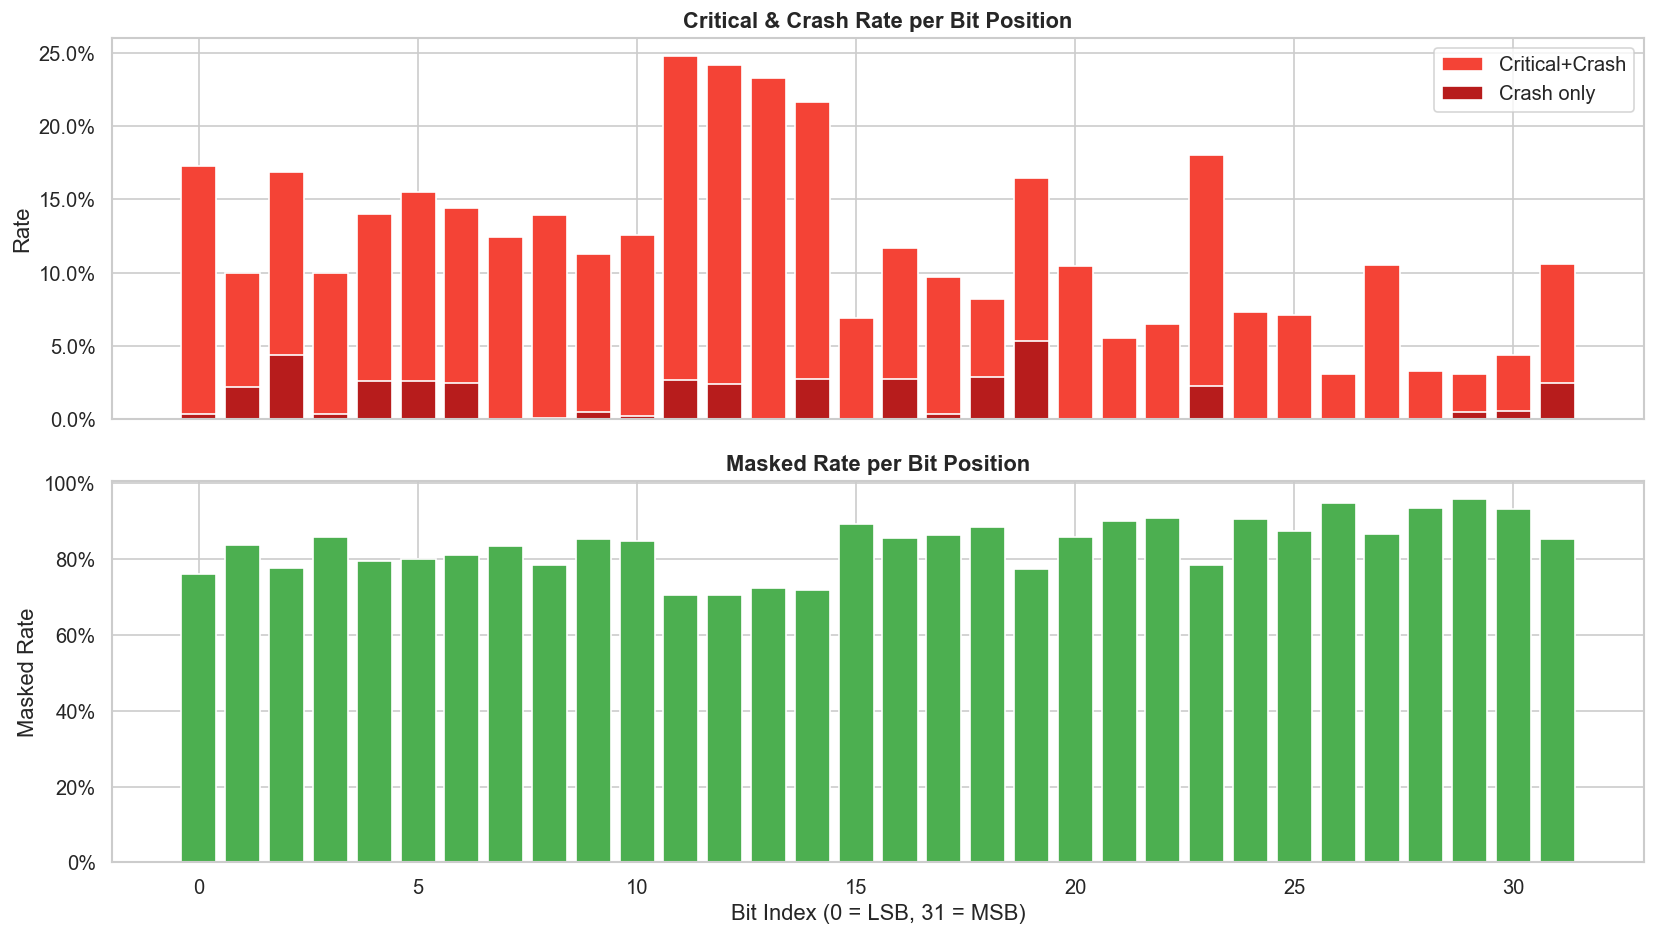

,bit_index,total,critical,degraded,crash,masked,critical_rate,crash_rate,masked_rate
0,0,3300,570,670,12,2508,0.1727,0.0036,0.7600
1,1,4600,460,557,100,3853,0.1000,0.0217,0.8376
2,2,4201,707,795,185,3266,0.1683,0.0440,0.7774
3,3,4700,468,501,18,4038,0.0996,0.0038,0.8591
4,4,4940,690,783,129,3923,0.1397,0.0261,0.7941
5,5,3800,589,685,100,3043,0.1550,0.0263,0.8008
6,6,4042,581,649,100,3274,0.1437,0.0247,0.8100
7,7,4136,513,593,0,3449,0.1240,0.0000,0.8339
8,8,2944,410,447,2,2312,0.1393,0.0007,0.7853
9,9,4525,509,557,22,3854,0.1125,0.0049,0.8517


In [14]:
bit_fc = df.groupby("bit_index").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "degraded": g["fault_class"].isin(DEGRADED_SET).sum(),
        "crash": (g["fault_class"] == "Crash").sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
    })
).reset_index()
bit_fc["bit_index"] = bit_fc["bit_index"].astype(int)
bit_fc["critical_rate"] = bit_fc["critical"] / bit_fc["total"]
bit_fc["crash_rate"] = bit_fc["crash"] / bit_fc["total"]
bit_fc["masked_rate"] = bit_fc["masked"] / bit_fc["total"]
bit_fc = bit_fc.sort_values("bit_index")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(bit_fc["bit_index"], bit_fc["critical_rate"], color="#F44336", label="Critical+Crash")
axes[0].bar(bit_fc["bit_index"], bit_fc["crash_rate"], color="#B71C1C", label="Crash only")
axes[0].set_ylabel("Rate")
axes[0].set_title("Critical & Crash Rate per Bit Position", fontweight="bold")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[1].bar(bit_fc["bit_index"], bit_fc["masked_rate"], color="#4CAF50")
axes[1].set_ylabel("Masked Rate")
axes[1].set_xlabel("Bit Index (0 = LSB, 31 = MSB)")
axes[1].set_title("Masked Rate per Bit Position", fontweight="bold")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability.png", bbox_inches="tight")
plt.show()

display(bit_fc.round(4))

## 8. Bit-Position Vulnerability by Register Class

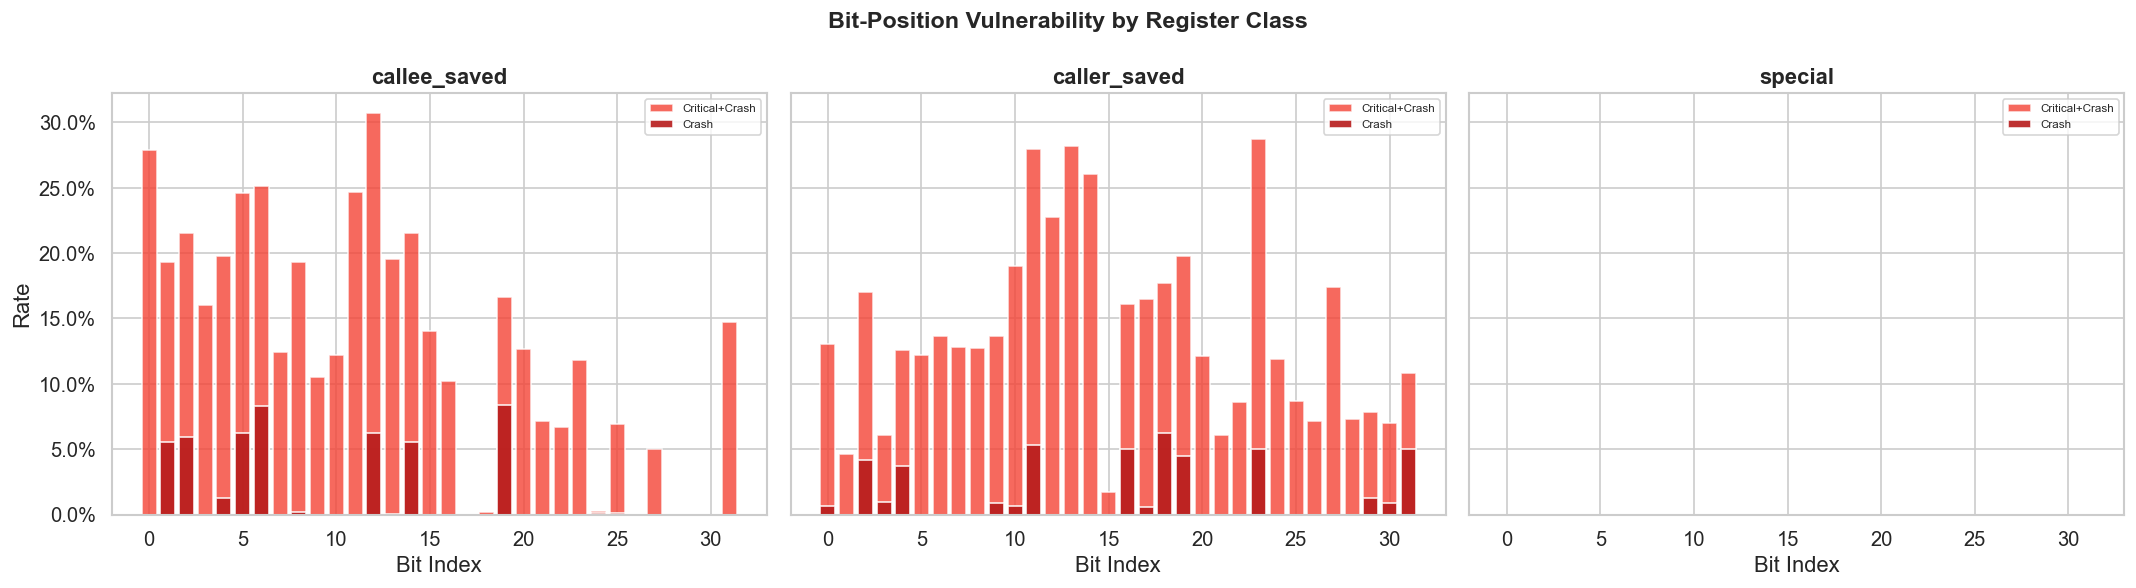

In [15]:
bit_cls = df.groupby(["register_class", "bit_index"]).apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0,
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g) if len(g) > 0 else 0,
    })
).reset_index()
bit_cls["bit_index"] = bit_cls["bit_index"].astype(int)

reg_classes = sorted(bit_cls["register_class"].unique())
fig, axes = plt.subplots(1, len(reg_classes), figsize=(6 * len(reg_classes), 5), sharey=True)
if len(reg_classes) == 1:
    axes = [axes]

for ax, rc in zip(axes, reg_classes):
    subset = bit_cls[bit_cls["register_class"] == rc].sort_values("bit_index")
    ax.bar(subset["bit_index"], subset["critical_rate"], color="#F44336", alpha=0.8, label="Critical+Crash")
    ax.bar(subset["bit_index"], subset["crash_rate"], color="#B71C1C", alpha=0.9, label="Crash")
    ax.set_title(f"{rc}", fontweight="bold")
    ax.set_xlabel("Bit Index")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.legend(fontsize=7)

axes[0].set_ylabel("Rate")
fig.suptitle("Bit-Position Vulnerability by Register Class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability_by_class.png", bbox_inches="tight")
plt.show()

## 9. Crash & Critical Failure Deep-Dive

Total critical/crash inferences: 38,282 (27.54%)
Unique faults causing critical/crash: 539 / 1390



fault_class,Crash,Critical,total_critical
register_name,,,
s1,1800,1589,3389
ra,3260,0,3260
s4,2400,814,3214
a0,2298,345,2643
s8,900,1170,2070
s7,1500,506,2006
a7,272,1691,1963
s3,1500,462,1962
t2,700,1072,1772


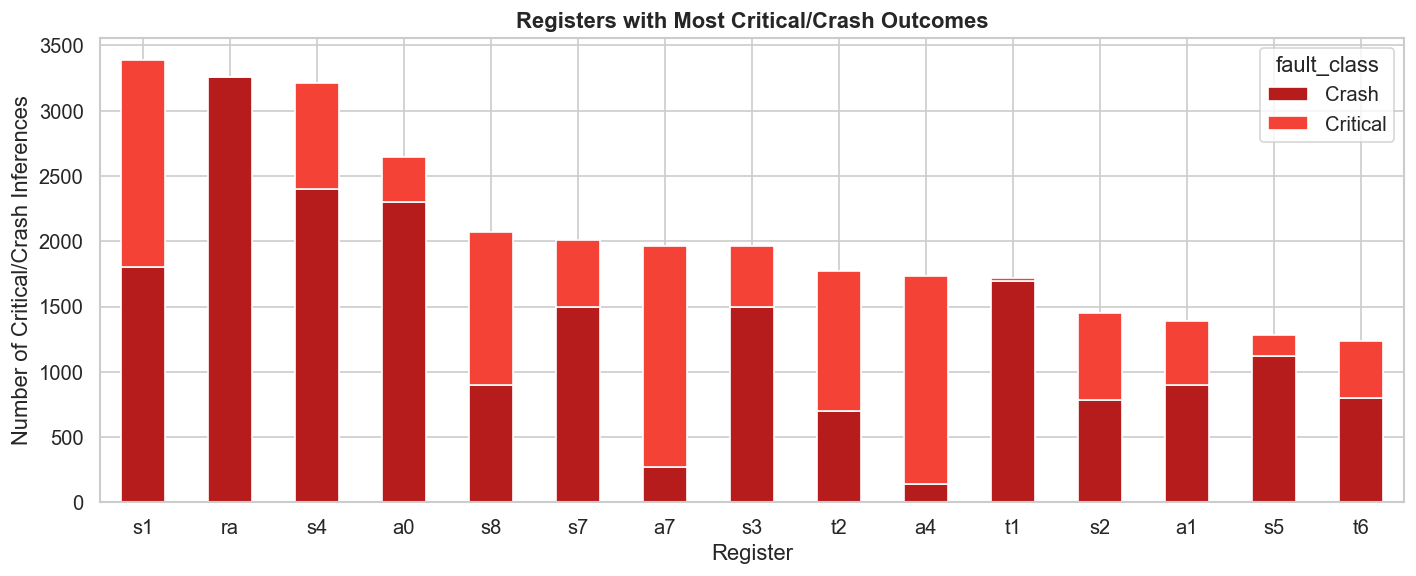

In [16]:
crit_df = df[df["fault_class"].isin(CRITICAL_SET)].copy()
print(f"Total critical/crash inferences: {len(crit_df):,} ({len(crit_df)/len(df)*100:.2f}%)")
print(f"Unique faults causing critical/crash: {crit_df['fault_id'].nunique()} / {df['fault_id'].nunique()}")
print()

# Which registers cause the most crashes?
crash_by_reg = crit_df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
crash_by_reg["total_critical"] = crash_by_reg.sum(axis=1)
crash_by_reg = crash_by_reg.sort_values("total_critical", ascending=False)
display(crash_by_reg.head(15))

# Top 10 most critical registers
fig, ax = plt.subplots(figsize=(12, 5))
top_crit_regs = crash_by_reg.head(15)
colors_stacked = []
for c in top_crit_regs.columns:
    if c == "total_critical":
        continue
    colors_stacked.append(SEVERITY_COLORS.get(c, "#999"))

plot_cols = [c for c in top_crit_regs.columns if c != "total_critical"]
top_crit_regs[plot_cols].plot.bar(stacked=True, ax=ax, color=colors_stacked, edgecolor="white")
ax.set_ylabel("Number of Critical/Crash Inferences")
ax.set_xlabel("Register")
ax.set_title("Registers with Most Critical/Crash Outcomes", fontweight="bold")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_crash_by_register.png", bbox_inches="tight")
plt.show()

## 10. Per-Fault Aggregated Vulnerability
For each unique fault injection, compute the fraction of images that were classified as critical/crash to identify the **most dangerous single-bit faults**.

In [17]:
fault_agg = df.groupby("fault_id").apply(
    lambda g: pd.Series({
        "register_name": g["register_name"].iloc[0],
        "register_class": g["register_class"].iloc[0],
        "bit_index": int(g["bit_index"].iloc[0]),
        "operator_index": int(g["operator_index"].iloc[0]),
        "operator_name": g["operator_name"].iloc[0] if "operator_name" in g.columns else "",
        "n_images": len(g),
        "n_critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "n_crash": (g["fault_class"] == "Crash").sum(),
        "n_masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g),
    })
).reset_index()

# Distribution of per-fault critical rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fault_agg["critical_rate"], bins=50, color="#F44336", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Critical+Crash Rate (per fault)")
axes[0].set_ylabel("Number of Faults")
axes[0].set_title("Distribution of Per-Fault Criticality")

axes[1].hist(fault_agg["crash_rate"], bins=50, color="#B71C1C", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Crash Rate (per fault)")
axes[1].set_ylabel("Number of Faults")
axes[1].set_title("Distribution of Per-Fault Crash Rate")

fig.suptitle("Per-Fault Vulnerability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_per_fault_distribution.png", bbox_inches="tight")
plt.show()

# Top 20 most dangerous faults
print("\nTop 20 most dangerous faults (by critical_rate):")
display(fault_agg.nlargest(20, "critical_rate")[
    ["fault_id", "register_name", "register_class", "bit_index",
     "operator_index", "operator_name", "n_images", "n_critical",
     "n_crash", "critical_rate", "crash_rate"]
])

ValueError: cannot convert float NaN to integer

## 11. Confidence Interval Estimation
Using Wilson score intervals for binomial proportions.

In [ ]:
def wilson_ci(successes, total, confidence=0.95):
    """Wilson score confidence interval for a binomial proportion."""
    if total == 0:
        return 0.0, 0.0, 0.0
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p_hat = successes / total
    denom = 1 + z**2 / total
    center = (p_hat + z**2 / (2 * total)) / denom
    margin = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * total)) / total) / denom
    return p_hat, max(0, center - margin), min(1, center + margin)

# CI per register
ci_rows = []
for reg, grp in df.groupby("register_name"):
    n = len(grp)
    n_crit = grp["fault_class"].isin(CRITICAL_SET).sum()
    n_crash = (grp["fault_class"] == "Crash").sum()
    p_crit, lo_crit, hi_crit = wilson_ci(n_crit, n)
    p_crash, lo_crash, hi_crash = wilson_ci(n_crash, n)
    ci_rows.append({
        "register": reg,
        "n": n,
        "critical_rate": p_crit,
        "critical_CI_lo": lo_crit,
        "critical_CI_hi": hi_crit,
        "crash_rate": p_crash,
        "crash_CI_lo": lo_crash,
        "crash_CI_hi": hi_crash,
    })

ci_df = pd.DataFrame(ci_rows).sort_values("critical_rate", ascending=False).reset_index(drop=True)
display(ci_df.round(4))

# Forest plot of CI
fig, ax = plt.subplots(figsize=(10, 10))
y_pos = np.arange(len(ci_df))
ax.barh(y_pos, ci_df["critical_rate"], xerr=[
    ci_df["critical_rate"] - ci_df["critical_CI_lo"],
    ci_df["critical_CI_hi"] - ci_df["critical_rate"]
], color="#F44336", alpha=0.7, capsize=3, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(ci_df["register"])
ax.set_xlabel("Critical+Crash Rate")
ax.set_title("Critical Rate per Register (95% Wilson CI)", fontweight="bold")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_ci_per_register.png", bbox_inches="tight")
plt.show()

## 12. Register × Bit Heatmap (Critical Rate)

In [ ]:
reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)
reg_bit_crit = reg_bit_crit.reindex(reg_order)
reg_bit_crit.columns = reg_bit_crit.columns.astype(int)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    reg_bit_crit, cmap="YlOrRd", linewidths=0.3, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical+Crash Rate"},
    vmin=0, vmax=max(reg_bit_crit.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Bit Position", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Bit Index (0=LSB → 31=MSB)")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_bit.png", bbox_inches="tight")
plt.show()

## 13. Impact on Model Accuracy
Compare the **golden accuracy** (no fault) against the effective accuracy under each fault scenario.

In [ ]:
# Golden accuracy
golden_correct = (df["golden_pred_class_ref"] == df["label"]).sum()
golden_acc = golden_correct / len(df)

# Faulty accuracy
faulty_correct = (df["pred_class"] == df["label"]).sum()
faulty_acc = faulty_correct / len(df)

print(f"Golden Accuracy : {golden_acc:.4f} ({golden_acc*100:.2f}%)")
print(f"Faulty Accuracy : {faulty_acc:.4f} ({faulty_acc*100:.2f}%)")
print(f"Accuracy Drop   : {(golden_acc - faulty_acc)*100:.2f} pp")

# Accuracy per register
acc_per_reg = df.groupby("register_name").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": ((g["golden_pred_class_ref"] == g["label"]).sum() - (g["pred_class"] == g["label"]).sum()) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(acc_per_reg))
w = 0.35
ax.bar(x - w/2, acc_per_reg["golden_accuracy"], w, label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_reg["faulty_accuracy"], w, label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_reg.index, rotation=45, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Golden vs Faulty Accuracy per Register", fontweight="bold")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_accuracy_per_register.png", bbox_inches="tight")
plt.show()

display(acc_per_reg.round(4))

## 14. Probability (Confidence) Degradation Analysis
For non-crash inferences, measure how fault injection affected the output confidence.

In [ ]:
ok_df = df[df["status"] == "ok"].copy()
ok_df["prob_delta"] = ok_df["top1_prob"] - ok_df["golden_top1_prob_ref"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ok_df["prob_delta"], bins=100, color="#2196F3", edgecolor="white", alpha=0.8)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Probability Delta (faulty - golden)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Confidence Change")

# Per register class
for rc in sorted(ok_df["register_class"].dropna().unique()):
    subset = ok_df[ok_df["register_class"] == rc]["prob_delta"]
    axes[1].hist(subset, bins=80, alpha=0.5, label=rc, density=True)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Probability Delta")
axes[1].set_ylabel("Density")
axes[1].set_title("Confidence Change by Register Class")
axes[1].legend()

fig.suptitle("Output Confidence Degradation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_confidence_degradation.png", bbox_inches="tight")
plt.show()

# Mean confidence delta per register
prob_stats = ok_df.groupby("register_name")["prob_delta"].agg(["mean", "std", "min", "max"]).sort_values("mean")
display(prob_stats.round(4))

## 15. Summary Table (LaTeX-ready)
Consolidated table for the paper.

In [ ]:
# Build per-register summary
summary_rows = []
for reg, grp in df.groupby("register_name"):
    n = len(grp)
    reg_class = grp["register_class"].iloc[0] if "register_class" in grp.columns else "?"
    fc = grp["fault_class"].value_counts()
    n_masked = fc.get("Masked", 0)
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    n_crash = fc.get("Crash", 0)
    acc = (grp["pred_class"] == grp["label"]).sum() / n
    p_crit, lo, hi = wilson_ci(n_crit, n)
    summary_rows.append({
        "Register": reg,
        "Class": reg_class,
        "N": n,
        "Masked %": round(n_masked / n * 100, 2),
        "Critical %": round(n_crit / n * 100, 2),
        "Crash %": round(n_crash / n * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
        "Accuracy %": round(acc * 100, 2),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Critical %", ascending=False).reset_index(drop=True)
display(summary_df)

# Overall
overall_n = len(df)
overall_fc = df["fault_class"].value_counts()
overall_crit = overall_fc.get("Critical", 0) + overall_fc.get("Crash", 0)
p, lo, hi = wilson_ci(overall_crit, overall_n)
print(f"\nOverall Critical+Crash Rate: {p*100:.2f}% [95% CI: {lo*100:.2f}% – {hi*100:.2f}%]")
print(f"Total faults sampled: {df['fault_id'].nunique()} / {len(pop)} population")

# LaTeX export
latex_str = summary_df.to_latex(index=False, float_format="%.2f", caption="Register fault injection resilience summary.", label="tab:register_resilience")
print("\n--- LaTeX Table ---")
print(latex_str)

## 16. Per Register-Class Summary (LaTeX-ready)

In [ ]:
cls_summary = []
for rc, grp in df.groupby("register_class"):
    n = len(grp)
    fc = grp["fault_class"].value_counts()
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    p, lo, hi = wilson_ci(n_crit, n)
    cls_summary.append({
        "Register Class": rc,
        "N": n,
        "Masked %": round(fc.get("Masked", 0) / n * 100, 2),
        "Acceptable %": round(fc.get("Acceptable", 0) / n * 100, 2),
        "Warning %": round(fc.get("Warning", 0) / n * 100, 2),
        "Critical %": round(fc.get("Critical", 0) / n * 100, 2),
        "Crash %": round(fc.get("Crash", 0) / n * 100, 2),
        "Crit+Crash %": round(p * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
    })

cls_summary_df = pd.DataFrame(cls_summary).sort_values("Crit+Crash %", ascending=False).reset_index(drop=True)
display(cls_summary_df)

latex_cls = cls_summary_df.to_latex(index=False, float_format="%.2f", caption="Resilience by RISC-V register class.", label="tab:register_class_resilience")
print("\n--- LaTeX Table ---")
print(latex_cls)

## 17. Export Analysis Artifacts

In [ ]:
export_dir = RUN_DIR / "notebook_exports"
export_dir.mkdir(exist_ok=True)

summary_df.to_csv(export_dir / "summary_per_register.csv", index=False)
cls_summary_df.to_csv(export_dir / "summary_per_register_class.csv", index=False)
ci_df.to_csv(export_dir / "confidence_intervals.csv", index=False)
bit_fc.to_csv(export_dir / "bit_vulnerability.csv", index=False)
fault_agg.to_csv(export_dir / "per_fault_aggregated.csv", index=False)
reg_fc.to_csv(export_dir / "classification_per_register.csv")
op_fc.to_csv(export_dir / "classification_per_operator.csv")

print(f"Exported {len(list(export_dir.glob('*')))} files to {export_dir}")
for f in sorted(export_dir.glob("*")):
    print(f"  {f.name} ({f.stat().st_size:,} bytes)")